In [1]:
from datetime import date
from dateutil.rrule import rrule, DAILY

from matplotlib import pyplot
%matplotlib inline

import numpy as np
import pandas as pd

import scipy.stats as ss
from sklearn import linear_model
import statsmodels.api as sm

In [2]:
df_vitals = pd.read_csv('vitals2.csv')

C:\ProgramData\Anaconda3\lib\site-packages\IPython\core\interactiveshell.py:3058: DtypeWarning: Columns (9,10,11,22,27,28,29) have mixed types. Specify dtype option on import or set low_memory=False.
  interactivity=interactivity, compiler=compiler, result=result)


In [3]:
df_vitals.head()

,created,eventTypeAndTimestamp,patient_uuid,timestamp,updated,BPM,DBP,DistanceTravel,FAHR,FAST,...,TimeAwake,TimeInBed,TimeSleep,device,deviceId,deviceModel,deviceVendor,height,identifier,location
0,NaN,VITALS-1451632080000,82591262,2015-12-31 23:08:00,NaN,NaN,112.0,NaN,NaN,NaN,...,NaN,NaN,NaN,MocaCuff,NaN,NaN,NaN,NaN,NaN,device
1,NaN,VITALS-1539117600000,82591262,2018-10-09 13:40:00,NaN,NaN,72.0,NaN,NaN,NaN,...,NaN,NaN,NaN,MocaCuff,NaN,NaN,NaN,NaN,NaN,device
2,NaN,VITALS-1539131940000,82591262,2018-10-09 17:39:00,NaN,NaN,84.0,NaN,NaN,NaN,...,NaN,NaN,NaN,MocaCuff,NaN,NaN,NaN,NaN,NaN,device
3,NaN,VITALS-1539132000000,82591262,2018-10-09 17:40:00,NaN,NaN,79.0,NaN,NaN,NaN,...,NaN,NaN,NaN,MocaCuff,NaN,NaN,NaN,NaN,NaN,device
4,NaN,VITALS-1539184020000,82591262,2018-10-10 08:07:00,NaN,NaN,88.0,NaN,NaN,NaN,...,NaN,NaN,NaN,MocaCuff,NaN,NaN,NaN,NaN,NaN,device


In [4]:
#convert the timestamp field from string to datetime data type
df_vitals['timestamp'] = pd.to_datetime(df_vitals['timestamp'],errors='coerce')

In [5]:
df_vitals.head()

,created,eventTypeAndTimestamp,patient_uuid,timestamp,updated,BPM,DBP,DistanceTravel,FAHR,FAST,...,TimeAwake,TimeInBed,TimeSleep,device,deviceId,deviceModel,deviceVendor,height,identifier,location
0,NaN,VITALS-1451632080000,82591262,2015-12-31 23:08:00,NaN,NaN,112.0,NaN,NaN,NaN,...,NaN,NaN,NaN,MocaCuff,NaN,NaN,NaN,NaN,NaN,device
1,NaN,VITALS-1539117600000,82591262,2018-10-09 13:40:00,NaN,NaN,72.0,NaN,NaN,NaN,...,NaN,NaN,NaN,MocaCuff,NaN,NaN,NaN,NaN,NaN,device
2,NaN,VITALS-1539131940000,82591262,2018-10-09 17:39:00,NaN,NaN,84.0,NaN,NaN,NaN,...,NaN,NaN,NaN,MocaCuff,NaN,NaN,NaN,NaN,NaN,device
3,NaN,VITALS-1539132000000,82591262,2018-10-09 17:40:00,NaN,NaN,79.0,NaN,NaN,NaN,...,NaN,NaN,NaN,MocaCuff,NaN,NaN,NaN,NaN,NaN,device
4,NaN,VITALS-1539184020000,82591262,2018-10-10 08:07:00,NaN,NaN,88.0,NaN,NaN,NaN,...,NaN,NaN,NaN,MocaCuff,NaN,NaN,NaN,NaN,NaN,device


In [6]:
# keep only the required fields 
df_vitals=df_vitals[['patient_uuid','timestamp','HR','SBP','DBP']]

In [7]:
df_vitals.head()

,patient_uuid,timestamp,HR,SBP,DBP
0,82591262,2015-12-31 23:08:00,67.0,161.0,112.0
1,82591262,2018-10-09 13:40:00,80.0,111.0,72.0
2,82591262,2018-10-09 17:39:00,79.0,134.0,84.0
3,82591262,2018-10-09 17:40:00,79.0,126.0,79.0
4,82591262,2018-10-10 08:07:00,53.0,137.0,88.0


In [8]:
# remove entries older than 2018 and newer than 11-Nov-2019. This step may or may not be needed.
# retaining it as-is for now
df_vitals=df_vitals[(df_vitals.timestamp>'2018-01-01')&(df_vitals.timestamp<'2019-11-11')]

# remove all na entries
df_vitals=df_vitals[~df_vitals['DBP'].isna()]
df_vitals=df_vitals[~df_vitals['SBP'].isna()]
df_vitals=df_vitals[~df_vitals['HR'].isna()]

In [9]:
# Let's start our analysis with the Systolic Blood Pressure. 
df_vitals_sbp = df_vitals[['timestamp','patient_uuid','SBP']]

In [10]:
df_vitals_sbp

,timestamp,patient_uuid,SBP
1,2018-10-09 13:40:00.000000,82591262,111.0
2,2018-10-09 17:39:00.000000,82591262,134.0
3,2018-10-09 17:40:00.000000,82591262,126.0
4,2018-10-10 08:07:00.000000,82591262,137.0
5,2018-10-10 14:02:00.000000,82591262,134.0
...,...,...,...
141927,2019-11-02 10:38:59.759999,81827529,126.0
141928,2019-11-02 14:17:59.759999,81827529,122.0
141929,2019-11-03 10:28:59.700000,81827529,127.0
141930,2019-11-03 15:17:59.700000,81827529,135.0


In [11]:
# extend the dataset to have a new field 
# that contains the date time value of the very first measurement available for each patient
# this information will later be used to derive additional column values of interest

df_vitals_sbp_minmaxtimes = pd.DataFrame(df_vitals_sbp.groupby('patient_uuid').agg({'timestamp' : np.min}))

df_vitals_sbp_minmaxtimes['timestamp'] = df_vitals_sbp_minmaxtimes['timestamp']

df_vitals_sbp_extended = pd.merge(df_vitals_sbp, df_vitals_sbp_minmaxtimes, on='patient_uuid')

In [12]:
df_vitals_sbp_extended

,timestamp_x,patient_uuid,SBP,timestamp_y
0,2018-10-09 13:40:00.000000,82591262,111.0,2018-10-09 13:40:00.000000
1,2018-10-09 17:39:00.000000,82591262,134.0,2018-10-09 13:40:00.000000
2,2018-10-09 17:40:00.000000,82591262,126.0,2018-10-09 13:40:00.000000
3,2018-10-10 08:07:00.000000,82591262,137.0,2018-10-09 13:40:00.000000
4,2018-10-10 14:02:00.000000,82591262,134.0,2018-10-09 13:40:00.000000
...,...,...,...,...
140789,2019-11-02 10:38:59.759999,81827529,126.0,2019-09-24 12:36:59.759999
140790,2019-11-02 14:17:59.759999,81827529,122.0,2019-09-24 12:36:59.759999
140791,2019-11-03 10:28:59.700000,81827529,127.0,2019-09-24 12:36:59.759999
140792,2019-11-03 15:17:59.700000,81827529,135.0,2019-09-24 12:36:59.759999


In [13]:
# In the extended dataset, add two additional columns that have the measurement date (without the time)
# and the start date (without the time)
# Again, this information will be used subsequently to derive additional features of interest
df_vitals_sbp_extended['reading_date'] = [dt.date() for dt in df_vitals_sbp_extended.timestamp_x]

df_vitals_sbp_extended['reading_start_date'] = [dt.date() for dt in df_vitals_sbp_extended.timestamp_y]

In [14]:
# for every reading, get the days elapsed since the first measurement date (note this is in days)
df_vitals_sbp_extended['days_elapsed'] = (df_vitals_sbp_extended['reading_date'] - df_vitals_sbp_extended['reading_start_date']).dt.days

In [15]:
# convert the new time stamp columns to date time data type
df_vitals_sbp_extended['timestamp_x'] = pd.to_datetime(df_vitals_sbp_extended['timestamp_x'])
df_vitals_sbp_extended['timestamp_y'] = pd.to_datetime(df_vitals_sbp_extended['timestamp_y'])

In [16]:
# Now, from the time component, get the hours since mid night for each measurement
# and extend it further to get the corresponding angle (24 hours = 360 degress, x hours = x*360/24)

df_vitals_sbp_extended['elapsed_time'] = df_vitals_sbp_extended['timestamp_x'] - df_vitals_sbp_extended['timestamp_y']
df_vitals_sbp_extended['angle'] = df_vitals_sbp_extended['elapsed_time'].diff() *360 / (np.timedelta64(1, 'h') *24)

# get the cosine and sine values corresponding to these angles
df_vitals_sbp_extended['sine'] = np.sin(df_vitals_sbp_extended['angle'])
df_vitals_sbp_extended['cos'] = np.cos(df_vitals_sbp_extended['angle'])

# drop NA
df_vitals_sbp_extended=df_vitals_sbp_extended[~df_vitals_sbp_extended['sine'].isna()]
df_vitals_sbp_extended=df_vitals_sbp_extended[~df_vitals_sbp_extended['cos'].isna()]


# get the cosine and sine values corresponding to the angles with a period T/2 = 12 hours
df_vitals_sbp_extended['sine.Tby2'] = np.sin(df_vitals_sbp_extended['angle']*2)
df_vitals_sbp_extended['cos.Tby2'] = np.cos(df_vitals_sbp_extended['angle']*2)

# drop NA
df_vitals_sbp_extended=df_vitals_sbp_extended[~df_vitals_sbp_extended['sine.Tby2'].isna()]
df_vitals_sbp_extended=df_vitals_sbp_extended[~df_vitals_sbp_extended['cos.Tby2'].isna()]

In [17]:
df_vitals_sbp_extended

,timestamp_x,patient_uuid,SBP,timestamp_y,reading_date,reading_start_date,days_elapsed,elapsed_time,angle,sine,cos,sine.Tby2,cos.Tby2
1,2018-10-09 17:39:00.000000,82591262,134.0,2018-10-09 13:40:00.000000,2018-10-09,2018-10-09,0,0 days 03:59:00,59.75000,-0.059704,-0.998216,0.119195,0.992871
2,2018-10-09 17:40:00.000000,82591262,126.0,2018-10-09 13:40:00.000000,2018-10-09,2018-10-09,0,0 days 04:00:00,0.25000,0.247404,0.968912,0.479426,0.877583
3,2018-10-10 08:07:00.000000,82591262,137.0,2018-10-09 13:40:00.000000,2018-10-10,2018-10-09,1,0 days 18:27:00,216.75000,0.019892,-0.999802,-0.039776,0.999209
4,2018-10-10 14:02:00.000000,82591262,134.0,2018-10-09 13:40:00.000000,2018-10-10,2018-10-09,1,1 days 00:22:00,88.75000,0.707112,0.707101,1.000000,-0.000015
5,2018-10-10 17:14:00.000000,82591262,163.0,2018-10-09 13:40:00.000000,2018-10-10,2018-10-09,1,1 days 03:34:00,48.00000,-0.768255,-0.640144,0.983588,-0.180430
...,...,...,...,...,...,...,...,...,...,...,...,...,...
140789,2019-11-02 10:38:59.759999,81827529,126.0,2019-09-24 12:36:59.759999,2019-11-02,2019-09-24,39,38 days 22:02:00,326.75000,0.024362,0.999703,0.048709,0.998813
140790,2019-11-02 14:17:59.759999,81827529,122.0,2019-09-24 12:36:59.759999,2019-11-02,2019-09-24,39,39 days 01:41:00,54.75000,-0.974149,-0.225904,0.440129,-0.897934
140791,2019-11-03 10:28:59.700000,81827529,127.0,2019-09-24 12:36:59.759999,2019-11-03,2019-09-24,40,39 days 21:51:59.940001,302.74975,0.915543,0.402221,0.736500,-0.676437
140792,2019-11-03 15:17:59.700000,81827529,135.0,2019-09-24 12:36:59.759999,2019-11-03,2019-09-24,40,40 days 02:40:59.940001,72.25000,0.006631,-0.999978,-0.013262,0.999912


In [18]:
# create a new column and extract the information on days between the current measurement and the previous measurement
df_vitals_sbp_extended['days_between_readings'] = -999

for patient_uuid in df_vitals_sbp_extended['patient_uuid'].unique():
    df_vitals_sbp_extended.loc[df_vitals_sbp_extended.patient_uuid == patient_uuid,'days_between_readings'] = (df_vitals_sbp_extended[df_vitals_sbp_extended.patient_uuid == patient_uuid]['days_elapsed'].shift(-1) - df_vitals_sbp_extended[df_vitals_sbp_extended.patient_uuid == patient_uuid]['days_elapsed']).shift(1)

In [19]:
# review this data for one patient just to make sure that the derived columns have the correct values
df_vitals_sbp_extended[df_vitals_sbp_extended.patient_uuid == 82591262]

,timestamp_x,patient_uuid,SBP,timestamp_y,reading_date,reading_start_date,days_elapsed,elapsed_time,angle,sine,cos,sine.Tby2,cos.Tby2,days_between_readings
1,2018-10-09 17:39:00,82591262,134.0,2018-10-09 13:40:00,2018-10-09,2018-10-09,0,0 days 03:59:00,59.75,-0.059704,-0.998216,0.119195,0.992871,NaN
2,2018-10-09 17:40:00,82591262,126.0,2018-10-09 13:40:00,2018-10-09,2018-10-09,0,0 days 04:00:00,0.25,0.247404,0.968912,0.479426,0.877583,0.0
3,2018-10-10 08:07:00,82591262,137.0,2018-10-09 13:40:00,2018-10-10,2018-10-09,1,0 days 18:27:00,216.75,0.019892,-0.999802,-0.039776,0.999209,1.0
4,2018-10-10 14:02:00,82591262,134.0,2018-10-09 13:40:00,2018-10-10,2018-10-09,1,1 days 00:22:00,88.75,0.707112,0.707101,1.000000,-0.000015,0.0
5,2018-10-10 17:14:00,82591262,163.0,2018-10-09 13:40:00,2018-10-10,2018-10-09,1,1 days 03:34:00,48.00,-0.768255,-0.640144,0.983588,-0.180430,0.0
6,2018-10-10 18:59:00,82591262,147.0,2018-10-09 13:40:00,2018-10-10,2018-10-09,1,1 days 05:19:00,26.25,0.898903,0.438148,0.787705,-0.616052,0.0
7,2018-10-11 04:35:00,82591262,154.0,2018-10-09 13:40:00,2018-10-11,2018-10-09,2,1 days 14:55:00,144.00,-0.491022,0.871147,-0.855504,0.517796,1.0
8,2018-10-11 20:15:00,82591262,141.0,2018-10-09 13:40:00,2018-10-11,2018-10-09,2,2 days 06:35:00,235.00,0.580587,-0.814198,-0.945426,0.325838,0.0
9,2018-10-11 20:16:00,82591262,133.0,2018-10-09 13:40:00,2018-10-11,2018-10-09,2,2 days 06:36:00,0.25,0.247404,0.968912,0.479426,0.877583,0.0
10,2018-10-12 09:37:00,82591262,138.0,2018-10-09 13:40:00,2018-10-12,2018-10-09,3,2 days 19:57:00,200.25,-0.725616,0.688099,-0.998592,-0.053038,1.0


In [20]:
# Now, we will split the measurements for each patients into multiple batches
# the batch contains successive measurements with a gap of no more than 3 days between two readings
# If the gap is higher, then there could be a big change that will throw off the interpolation
# the 3 here is a hyperparameter which may need to be tuned
df_vitals_sbp_extended['batch'] = 0

df_vitals_sbp_extended.loc[df_vitals_sbp_extended['days_between_readings'] > 3,'batch'] = 1

for patient_uuid in df_vitals_sbp_extended['patient_uuid'].unique():
    df_vitals_sbp_extended.loc[df_vitals_sbp_extended.patient_uuid == patient_uuid,'batch'] = df_vitals_sbp_extended[df_vitals_sbp_extended.patient_uuid == patient_uuid]['batch'].cumsum()

In [21]:
df_vitals_sbp_extended.head(60)

,timestamp_x,patient_uuid,SBP,timestamp_y,reading_date,reading_start_date,days_elapsed,elapsed_time,angle,sine,cos,sine.Tby2,cos.Tby2,days_between_readings,batch
1,2018-10-09 17:39:00.000,82591262,134.0,2018-10-09 13:40:00.000,2018-10-09,2018-10-09,0,0 days 03:59:00,59.75,-0.059704,-0.998216,0.119195,0.992871,NaN,0
2,2018-10-09 17:40:00.000,82591262,126.0,2018-10-09 13:40:00.000,2018-10-09,2018-10-09,0,0 days 04:00:00,0.25,0.247404,0.968912,0.479426,0.877583,0.0,0
3,2018-10-10 08:07:00.000,82591262,137.0,2018-10-09 13:40:00.000,2018-10-10,2018-10-09,1,0 days 18:27:00,216.75,0.019892,-0.999802,-0.039776,0.999209,1.0,0
4,2018-10-10 14:02:00.000,82591262,134.0,2018-10-09 13:40:00.000,2018-10-10,2018-10-09,1,1 days 00:22:00,88.75,0.707112,0.707101,1.000000,-0.000015,0.0,0
5,2018-10-10 17:14:00.000,82591262,163.0,2018-10-09 13:40:00.000,2018-10-10,2018-10-09,1,1 days 03:34:00,48.00,-0.768255,-0.640144,0.983588,-0.180430,0.0,0
6,2018-10-10 18:59:00.000,82591262,147.0,2018-10-09 13:40:00.000,2018-10-10,2018-10-09,1,1 days 05:19:00,26.25,0.898903,0.438148,0.787705,-0.616052,0.0,0
7,2018-10-11 04:35:00.000,82591262,154.0,2018-10-09 13:40:00.000,2018-10-11,2018-10-09,2,1 days 14:55:00,144.00,-0.491022,0.871147,-0.855504,0.517796,1.0,0
8,2018-10-11 20:15:00.000,82591262,141.0,2018-10-09 13:40:00.000,2018-10-11,2018-10-09,2,2 days 06:35:00,235.00,0.580587,-0.814198,-0.945426,0.325838,0.0,0
9,2018-10-11 20:16:00.000,82591262,133.0,2018-10-09 13:40:00.000,2018-10-11,2018-10-09,2,2 days 06:36:00,0.25,0.247404,0.968912,0.479426,0.877583,0.0,0
10,2018-10-12 09:37:00.000,82591262,138.0,2018-10-09 13:40:00.000,2018-10-12,2018-10-09,3,2 days 19:57:00,200.25,-0.725616,0.688099,-0.998592,-0.053038,1.0,0


In [22]:
# Now we will start fitting a cosinor model for each batch for each patient
# the original mathematical expression for the model is: Y = M + a cos(t + phi)
# where phi represents the offset from midnight for the first measurement. 
# This can be rewritten as: Y = M + a cos(t) + b sin(t), which is used for the modelling
# refer https://link.springer.com/content/pdf/10.3758/BF03200975.pdf where this idea is inspired from

# I use sklearn to do the fit. But to validate I also fit using statmodel package Ordinary Linear Regression
# In the below script, I terminate at the first batch to do the validations. 

for patient_uuid in df_vitals_sbp_extended['patient_uuid'].unique():
    df_vitals_subset = df_vitals_sbp_extended[df_vitals_sbp_extended['patient_uuid'] == patient_uuid]
    for batch in df_vitals_subset['batch'].unique():
        df_vitals_subset_batch = df_vitals_subset[df_vitals_subset['batch'] == batch]
        if df_vitals_subset_batch.shape[0] > 10:
            X = df_vitals_subset_batch[['cos','sine']]
            y = df_vitals_subset_batch[['SBP']]
            lm = linear_model.LinearRegression()
            print("patient: " + str(patient_uuid) + ", batch: " + str(batch))
            model = lm.fit(X,y)
            print(lm.coef_)
            print(lm.intercept_)
            
            
            X = df_vitals_subset_batch[['cos','sine']]
            X = sm.add_constant(X)
            y = df_vitals_subset_batch[['SBP']]
            model = sm.OLS(y, X).fit()
            print(model.summary())

            break
    break

patient: 82591262, batch: 0
[[ 0.29451609 -9.40593242]]
[137.48487075]
                            OLS Regression Results                            
Dep. Variable:                    SBP   R-squared:                       0.167
Model:                            OLS   Adj. R-squared:                  0.069
Method:                 Least Squares   F-statistic:                     1.703
Date:                Sun, 23 Feb 2020   Prob (F-statistic):              0.212
Time:                        11:06:22   Log-Likelihood:                -76.808
No. Observations:                  20   AIC:                             159.6
Df Residuals:                      17   BIC:                             162.6
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------

C:\ProgramData\Anaconda3\lib\site-packages\numpy\core\fromnumeric.py:2389: FutureWarning: Method .ptp is deprecated and will be removed in a future version. Use numpy.ptp instead.
  return ptp(axis=axis, out=out, **kwargs)


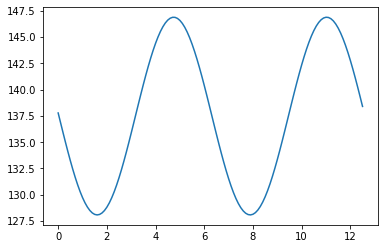

In [23]:
# Both the outputs above show same values for coefficients to most extent
# since they are using two different but well tested publicly available packages
# However, haven't done any tuning

# Lets take these coefficients and visualize how the cosnior looks like for this one batch for the specific patient
theta = np.arange(0,4*np.pi,0.1)
curve = lm.intercept_ * np.ones(len(theta)) + lm.coef_[0][0]*np.cos(theta)+ lm.coef_[0][1]*np.sin(theta)
pyplot.plot(theta,curve)
pyplot.show()

C:\ProgramData\Anaconda3\lib\site-packages\pandas\plotting\_matplotlib\converter.py:103: FutureWarning: Using an implicitly registered datetime converter for a matplotlib plotting method. The converter was registered by pandas on import. Future versions of pandas will require you to explicitly register matplotlib converters.

To register the converters:
	>>> from pandas.plotting import register_matplotlib_converters
	>>> register_matplotlib_converters()
  warnings.warn(msg, FutureWarning)


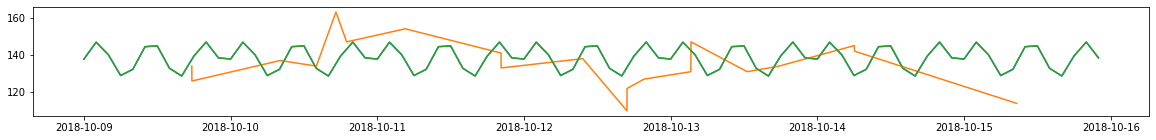

In [24]:
# Now I try to overlay two plots:
# the first is the generated data based on the model
# the second is the actual time series data for the patient for the first batch

dt_min = df_vitals_subset_batch.min()['timestamp_x']
dt_max = df_vitals_subset_batch.max()['timestamp_x']

min_date = dt_min.date()
max_date = dt_max.date()


hours = ['00:00:00', '02:00:00', '04:00:00', '06:00:00', '08:00:00', '10:00:00', '12:00:00', '14:00:00', '16:00:00', '18:00:00', '20:00:00', '22:00:00']
hours_angles = [0, 30, 60, 90, 120, 150, 180, 210, 240, 270, 300, 330]

hour_iters = np.arange(0,12)

from datetime import date
from dateutil.rrule import rrule, DAILY

df_interpolated = pd.DataFrame(columns = ['timestamp_x','SBP'])

for date_iter in rrule(DAILY, dtstart=min_date, until=max_date):
    for hour_iter in hour_iters:
        timestamp = pd.to_datetime(date_iter + pd.to_timedelta(hours[hour_iter]))
        data =  lm.intercept_ + lm.coef_[0][0] * np.cos(hours_angles[hour_iter]) +  lm.coef_[0][1]*np.sin(hours_angles[hour_iter])
        
        df_interpolated.loc[len(df_interpolated)] = [timestamp, data]

#df_interpolated.plot(kind = 'line', x='timestamp_x',y='SBP')
#df_vitals_subset_batch.plot(kind='line',x='timestamp_x',y=['from_cosnior','SBP'])
        
        
fig = pyplot.figure(figsize=(20, 2))

#ax = fig.add_subplot(111)
#ax.plot(x, y)

for frame in [df_interpolated,df_vitals_subset_batch[['timestamp_x','SBP']], df_interpolated]:
    pyplot.plot(frame['timestamp_x'], frame['SBP'])

#pyplot.xlim(0,18000)
#pyplot.ylim(0,30)
pyplot.show()




In [25]:
# Now I add the days elapsed as the additional factor and fit a new model
# the mathematical expression is: Y = M + a cos(t) + b sin(t) + d
# this is to account for a trend over days
# Note that if the batch is spread over a large number of days then the trend would not hold up 
# since in practice we would assume there would be some intervention if the BP is going very high or very low
for patient_uuid in df_vitals_sbp_extended['patient_uuid'].unique():
    df_vitals_subset = df_vitals_sbp_extended[df_vitals_sbp_extended['patient_uuid'] == patient_uuid]
    for batch in df_vitals_subset['batch'].unique():
        df_vitals_subset_batch = df_vitals_subset[df_vitals_subset['batch'] == batch]
        if df_vitals_subset_batch.shape[0] > 10:
            X = df_vitals_subset_batch[['cos','sine','days_elapsed']]
            y = df_vitals_subset_batch[['SBP']]
            lm = linear_model.LinearRegression()
            print("patient: " + str(patient_uuid) + ", batch: " + str(batch))
            model = lm.fit(X,y)
            print(lm.coef_)
            print(lm.intercept_)

            break
    break

patient: 82591262, batch: 0
[[ 0.21256569 -8.66735898 -1.189601  ]]
[140.54449177]


1260


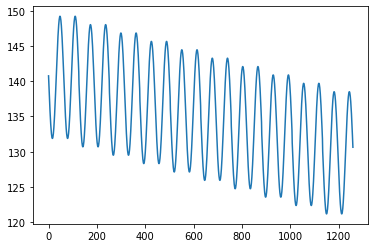

In [26]:
# Again, lets take these coefficients and visualize how the cosnior looks like for this one batch for the specific patient
theta = np.arange(0,4*np.pi,0.1)
days_elapsed = np.arange(0,10)
xaxis = np.arange(0,len(theta)*len(days_elapsed))
curve = []
for i in days_elapsed:
    curve_i = lm.intercept_ * np.ones(len(theta)) + lm.coef_[0][0]*np.cos(theta)+ lm.coef_[0][1]*np.sin(theta) + (lm.coef_[0][2])*i*np.ones(len(theta))
    curve.extend(curve_i)
print(len(curve))
pyplot.plot(xaxis,curve)
pyplot.show()

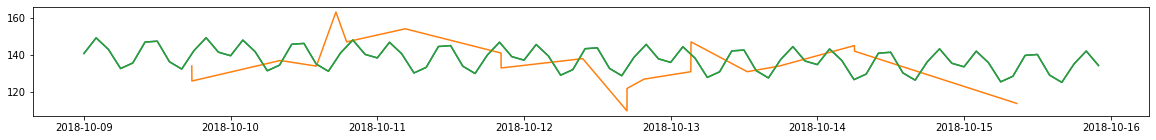

In [27]:
# Now again I try to overlay two plots:
# the first is the generated data based on the new model
# the second is the actual time series data for the patient for the first batch

dt_min = df_vitals_subset_batch.min()['timestamp_x']
dt_max = df_vitals_subset_batch.max()['timestamp_x']

min_date = dt_min.date()
max_date = dt_max.date()


hours = ['00:00:00', '02:00:00', '04:00:00', '06:00:00', '08:00:00', '10:00:00', '12:00:00', '14:00:00', '16:00:00', '18:00:00', '20:00:00', '22:00:00']
hours_angles = [0, 30, 60, 90, 120, 150, 180, 210, 240, 270, 300, 330]

hour_iters = np.arange(0,12)

from datetime import date
from dateutil.rrule import rrule, DAILY

df_interpolated = pd.DataFrame(columns = ['timestamp_x','SBP'])

days_elapsed = 0
for date_iter in rrule(DAILY, dtstart=min_date, until=max_date):
    for hour_iter in hour_iters:
        timestamp = pd.to_datetime(date_iter + pd.to_timedelta(hours[hour_iter]))
        data =  lm.intercept_ + lm.coef_[0][0] * np.cos(hours_angles[hour_iter]) +  lm.coef_[0][1]*np.sin(hours_angles[hour_iter]) + (lm.coef_[0][2]*days_elapsed)
        
        df_interpolated.loc[len(df_interpolated)] = [timestamp, data]

    days_elapsed = days_elapsed + 1

#df_interpolated.plot(kind = 'line', x='timestamp_x',y='SBP')
#df_vitals_subset_batch.plot(kind='line',x='timestamp_x',y=['from_cosnior','SBP'])
        
        
fig = pyplot.figure(figsize=(20, 2))

#ax = fig.add_subplot(111)
#ax.plot(x, y)

for frame in [df_interpolated,df_vitals_subset_batch[['timestamp_x','SBP']], df_interpolated]:
    pyplot.plot(frame['timestamp_x'], frame['SBP'])

#pyplot.xlim(0,18000)
#pyplot.ylim(0,30)
pyplot.show()

In [28]:
# Now I add the days elapsed as the additional factor and fit a new model
# the mathematical expression is: Y = M + a cos(t/2) + b sin(t/2) + d
# this is to account for a trend over days
# Note that if the batch is spread over a large number of days then the trend would not hold up 
# since in practice we would assume there would be some intervention if the BP is going very high or very low
for patient_uuid in df_vitals_sbp_extended['patient_uuid'].unique():
    df_vitals_subset = df_vitals_sbp_extended[df_vitals_sbp_extended['patient_uuid'] == patient_uuid]
    for batch in df_vitals_subset['batch'].unique():
        df_vitals_subset_batch = df_vitals_subset[df_vitals_subset['batch'] == batch]
        if df_vitals_subset_batch.shape[0] > 10:
            X = df_vitals_subset_batch[['cos.Tby2','sine.Tby2','days_elapsed']]
            y = df_vitals_subset_batch[['SBP']]
            lm = linear_model.LinearRegression()
            print("patient: " + str(patient_uuid) + ", batch: " + str(batch))
            model = lm.fit(X,y)
            print(lm.coef_)
            print(lm.intercept_)

            break
    break

patient: 82591262, batch: 0
[[ 1.85553707  1.35683908 -1.46039422]]
[138.81847601]


1260


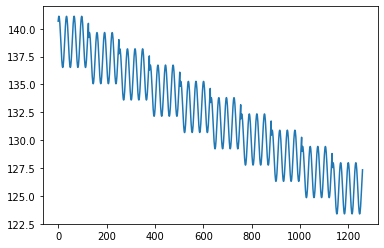

In [29]:
# Again, lets take these coefficients and visualize how the cosnior looks like for this one batch for the specific patient
theta = np.arange(0,4*np.pi,0.1)
days_elapsed = np.arange(0,10)
xaxis = np.arange(0,len(theta)*len(days_elapsed))
curve = []
for i in days_elapsed:
    curve_i = lm.intercept_ * np.ones(len(theta)) + lm.coef_[0][0]*np.cos(theta*2)+ lm.coef_[0][1]*np.sin(theta*2) + (lm.coef_[0][2])*i*np.ones(len(theta))
    curve.extend(curve_i)
print(len(curve))
pyplot.plot(xaxis,curve)
pyplot.show()

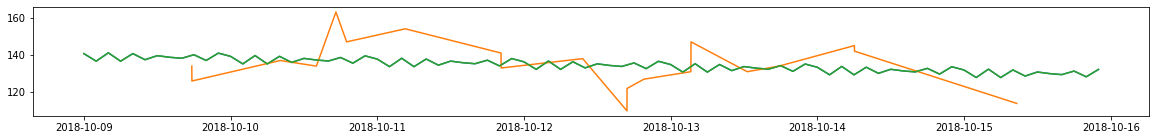

In [30]:
# Now again I try to overlay two plots:
# the first is the generated data based on the new model
# the second is the actual time series data for the patient for the first batch

dt_min = df_vitals_subset_batch.min()['timestamp_x']
dt_max = df_vitals_subset_batch.max()['timestamp_x']

min_date = dt_min.date()
max_date = dt_max.date()


hours = ['00:00:00', '02:00:00', '04:00:00', '06:00:00', '08:00:00', '10:00:00', '12:00:00', '14:00:00', '16:00:00', '18:00:00', '20:00:00', '22:00:00']
hours_angles = [0, 30, 60, 90, 120, 150, 180, 210, 240, 270, 300, 330]

hour_iters = np.arange(0,12)

from datetime import date
from dateutil.rrule import rrule, DAILY

df_interpolated = pd.DataFrame(columns = ['timestamp_x','SBP'])

days_elapsed = 0
for date_iter in rrule(DAILY, dtstart=min_date, until=max_date):
    for hour_iter in hour_iters:
        timestamp = pd.to_datetime(date_iter + pd.to_timedelta(hours[hour_iter]))
        data =  lm.intercept_ + lm.coef_[0][0] * np.cos(hours_angles[hour_iter]*2) +  lm.coef_[0][1]*np.sin(hours_angles[hour_iter]*2) + (lm.coef_[0][2]*days_elapsed)
        
        df_interpolated.loc[len(df_interpolated)] = [timestamp, data]

    days_elapsed = days_elapsed + 1

#df_interpolated.plot(kind = 'line', x='timestamp_x',y='SBP')
#df_vitals_subset_batch.plot(kind='line',x='timestamp_x',y=['from_cosnior','SBP'])
        
        
fig = pyplot.figure(figsize=(20, 2))

#ax = fig.add_subplot(111)
#ax.plot(x, y)

for frame in [df_interpolated,df_vitals_subset_batch[['timestamp_x','SBP']], df_interpolated]:
    pyplot.plot(frame['timestamp_x'], frame['SBP'])

#pyplot.xlim(0,18000)
#pyplot.ylim(0,30)
pyplot.show()

In [31]:
# Now I add the days elapsed as the additional factor and fit a new model
# the mathematical expression is: Y = M + a cos(t) + d*days_elapsed
# this is to account for a trend over days
# Note that if the batch is spread over a large number of days then the trend would not hold up 
# since in practice we would assume there would be some intervention if the BP is going very high or very low
for patient_uuid in df_vitals_sbp_extended['patient_uuid'].unique():
    df_vitals_subset = df_vitals_sbp_extended[df_vitals_sbp_extended['patient_uuid'] == patient_uuid]
    for batch in df_vitals_subset['batch'].unique():
        df_vitals_subset_batch = df_vitals_subset[df_vitals_subset['batch'] == batch]
        if df_vitals_subset_batch.shape[0] > 10:
            X = df_vitals_subset_batch[['cos','days_elapsed']]
            y = df_vitals_subset_batch[['SBP']]
            lm = linear_model.LinearRegression()
            print("patient: " + str(patient_uuid) + ", batch: " + str(batch))
            model = lm.fit(X,y)
            print(lm.coef_)
            print(lm.intercept_)

            break
    break

patient: 82591262, batch: 0
[[ 0.34712408 -1.73705489]]
[140.16907298]


1260


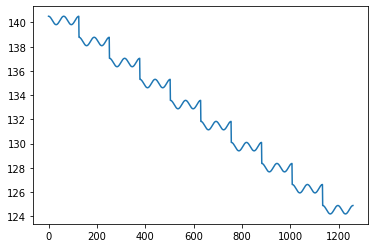

In [32]:
# Again, lets take these coefficients and visualize how the cosnior looks like for this one batch for the specific patient
theta = np.arange(0,4*np.pi,0.1)
days_elapsed = np.arange(0,10)
xaxis = np.arange(0,len(theta)*len(days_elapsed))
curve = []
for i in days_elapsed:
    curve_i = lm.intercept_ * np.ones(len(theta)) + lm.coef_[0][0]*np.cos(theta) + (lm.coef_[0][1])*i*np.ones(len(theta))
    curve.extend(curve_i)
print(len(curve))
pyplot.plot(xaxis,curve)
pyplot.show()

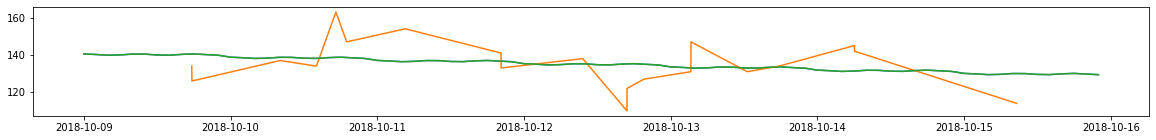

In [33]:
# Now again I try to overlay two plots:
# the first is the generated data based on the new model
# the second is the actual time series data for the patient for the first batch

dt_min = df_vitals_subset_batch.min()['timestamp_x']
dt_max = df_vitals_subset_batch.max()['timestamp_x']

min_date = dt_min.date()
max_date = dt_max.date()


hours = ['00:00:00', '02:00:00', '04:00:00', '06:00:00', '08:00:00', '10:00:00', '12:00:00', '14:00:00', '16:00:00', '18:00:00', '20:00:00', '22:00:00']
hours_angles = [0, 30, 60, 90, 120, 150, 180, 210, 240, 270, 300, 330]

hour_iters = np.arange(0,12)

df_interpolated = pd.DataFrame(columns = ['timestamp_x','SBP'])

days_elapsed = 0
for date_iter in rrule(DAILY, dtstart=min_date, until=max_date):
    for hour_iter in hour_iters:
        timestamp = pd.to_datetime(date_iter + pd.to_timedelta(hours[hour_iter]))
        data =  lm.intercept_ + lm.coef_[0][0] * np.cos(hours_angles[hour_iter]) + (lm.coef_[0][1]*days_elapsed)
        
        df_interpolated.loc[len(df_interpolated)] = [timestamp, data]

    days_elapsed = days_elapsed + 1

#df_interpolated.plot(kind = 'line', x='timestamp_x',y='SBP')
#df_vitals_subset_batch.plot(kind='line',x='timestamp_x',y=['from_cosnior','SBP'])
        
        
fig = pyplot.figure(figsize=(20, 2))

#ax = fig.add_subplot(111)
#ax.plot(x, y)

for frame in [df_interpolated,df_vitals_subset_batch[['timestamp_x','SBP']], df_interpolated]:
    pyplot.plot(frame['timestamp_x'], frame['SBP'])

#pyplot.xlim(0,18000)
#pyplot.ylim(0,30)
pyplot.show()

In [34]:
# Now I add the days elapsed as the additional factor and fit a new model
# the mathematical expression is: Y = M + a*cos(t) + b* sin(t) + c*cos(t/2) + d*sin(t/2) + e*days_elapsed
# this is to account for a trend over days
# Note that if the batch is spread over a large number of days then the trend would not hold up 
# since in practice we would assume there would be some intervention if the BP is going very high or very low
for patient_uuid in df_vitals_sbp_extended['patient_uuid'].unique():
    df_vitals_subset = df_vitals_sbp_extended[df_vitals_sbp_extended['patient_uuid'] == patient_uuid]
    for batch in df_vitals_subset['batch'].unique():
        df_vitals_subset_batch = df_vitals_subset[df_vitals_subset['batch'] == batch]
        if df_vitals_subset_batch.shape[0] > 10:
            X = df_vitals_subset_batch[['cos','sine','cos.Tby2','sine.Tby2','days_elapsed']]
            y = df_vitals_subset_batch[['SBP']]
            lm = linear_model.LinearRegression()
            print("patient: " + str(patient_uuid) + ", batch: " + str(batch))
            model = lm.fit(X,y)
            print(lm.coef_)
            print(lm.intercept_)

            break
    break

patient: 82591262, batch: 0
[[-0.08779388 -9.12529704 -0.99641734  1.61533797 -0.88587725]]
[140.17969994]


1260


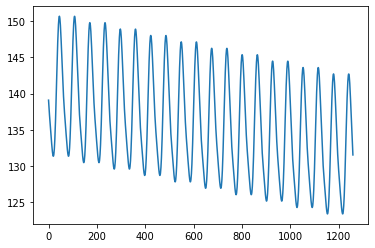

In [35]:
# Again, lets take these coefficients and visualize how the cosnior looks like for this one batch for the specific patient
theta = np.arange(0,4*np.pi,0.1)
days_elapsed = np.arange(0,10)
xaxis = np.arange(0,len(theta)*len(days_elapsed))
curve = []
for i in days_elapsed:
    curve_i = lm.intercept_ * np.ones(len(theta)) + lm.coef_[0][0]*np.cos(theta) + lm.coef_[0][1]*np.sin(theta) + lm.coef_[0][2]*np.cos(theta*2) + lm.coef_[0][3]*np.sin(theta*2) + (lm.coef_[0][4])*i*np.ones(len(theta))
    curve.extend(curve_i)
print(len(curve))
pyplot.plot(xaxis,curve)
pyplot.show()

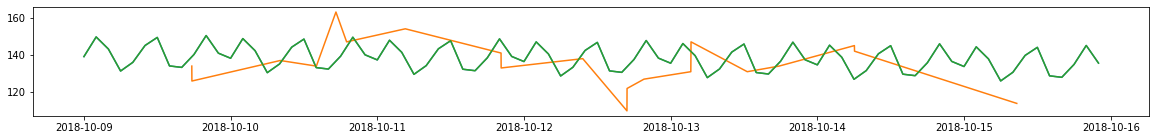

In [36]:
# Now again I try to overlay two plots:
# the first is the generated data based on the new model
# the second is the actual time series data for the patient for the first batch

dt_min = df_vitals_subset_batch.min()['timestamp_x']
dt_max = df_vitals_subset_batch.max()['timestamp_x']

min_date = dt_min.date()
max_date = dt_max.date()


hours = ['00:00:00', '02:00:00', '04:00:00', '06:00:00', '08:00:00', '10:00:00', '12:00:00', '14:00:00', '16:00:00', '18:00:00', '20:00:00', '22:00:00']
hours_angles = [0, 30, 60, 90, 120, 150, 180, 210, 240, 270, 300, 330]

hour_iters = np.arange(0,12)

df_interpolated = pd.DataFrame(columns = ['timestamp_x','SBP'])

days_elapsed = 0
for date_iter in rrule(DAILY, dtstart=min_date, until=max_date):
    for hour_iter in hour_iters:
        timestamp = pd.to_datetime(date_iter + pd.to_timedelta(hours[hour_iter]))
        data =  lm.intercept_ + lm.coef_[0][0] * np.cos(hours_angles[hour_iter]) + lm.coef_[0][1] * np.sin(hours_angles[hour_iter]) + lm.coef_[0][2] * np.cos(hours_angles[hour_iter]*2) + lm.coef_[0][3] * np.sin(hours_angles[hour_iter]*2) + (lm.coef_[0][4]*days_elapsed)
        
        df_interpolated.loc[len(df_interpolated)] = [timestamp, data]

    days_elapsed = days_elapsed + 1

#df_interpolated.plot(kind = 'line', x='timestamp_x',y='SBP')
#df_vitals_subset_batch.plot(kind='line',x='timestamp_x',y=['from_cosnior','SBP'])
        
        
fig = pyplot.figure(figsize=(20, 2))

#ax = fig.add_subplot(111)
#ax.plot(x, y)

for frame in [df_interpolated,df_vitals_subset_batch[['timestamp_x','SBP']], df_interpolated]:
    pyplot.plot(frame['timestamp_x'], frame['SBP'])

#pyplot.xlim(0,18000)
#pyplot.ylim(0,30)
pyplot.show()

In [37]:
# Feedback points from Naman on 02/09:

# Use SBP instead of DBP (status: done)

# incorporate new data set (status: in progress, Owner: Suman/may need help)

# test with cosine alone (no phi) and cosine/phi (status: done  - Owner: Suman) 

# change the period of each cosine (eg. T, T/2) (status: done - Owner: Suman)

# convert to a regression model eg. moving window of last four days as the features (time series may have patterns)
# (status: pending, Owner: Suman)

# try LSTM, NNAR (status: done - Owner: Patrick)

# transfer learning (incorporate learning from model based on one patient to other patients) 
# (status: cut - Owner: can anyone else on the team help with this?)

# also notes data could have some signals like a patient not feeling well on a certain day or change of medication etc.
# (status: pending - Owner: Ankit)

# confidence intervals (a week if we have a lot of data) (status: pending, owner: Ankit)

# curve fitting (stretch) (status: cut)

